# Butterfly Detector — Leeds Butterfly Dataset (5 species)

**CSCI1409 Deep Learning bonus project — KBTU**

This notebook trains YOLOv8n to detect and classify butterflies. It loads the Leeds Butterfly Dataset (from Google Drive, or downloads it from Zenodo), converts segmentation masks into bounding boxes, filters to five species, groups near-duplicates before splitting, trains two controlled experiments (640 px baseline and 416 px experiment), compares them on validation, selects the final model with an explicit, pre-declared rule (validation mAP50; ties keep the baseline), and evaluates the selected model on the test set once.

**Run top-to-bottom in Google Colab.** Recommended: Runtime → Change runtime type → T4 GPU. The dataset download is large (~476 MB).

## 0. Setup

In [21]:
%pip -q install ultralytics imagehash

import os, re, time, random, shutil, json, zipfile, hashlib, urllib.request
from pathlib import Path
import numpy as np, pandas as pd, cv2, imagehash
import matplotlib.pyplot as plt
from PIL import Image
import torch, ultralytics
from ultralytics import YOLO

print("Ultralytics:", ultralytics.__version__)
print("PyTorch:", torch.__version__)
print("NumPy:", np.__version__)

# Save environment versions for reproducibility
!pip freeze | grep -iE "^(ultralytics|torch|torchvision|numpy|opencv-python|imagehash|pandas|matplotlib|pillow)==" > requirements.txt
print(Path("requirements.txt").read_text())

Ultralytics: 8.4.216
PyTorch: 2.14.1+cu130
NumPy: 2.4.6
ImageHash==4.3.2
matplotlib==3.10.0
numpy==2.4.6
opencv-python==5.0.0.93
pandas==2.2.3
pillow==11.3.0
torch==2.14.1+cu130
torchvision==0.29.1+cu130
ultralytics==8.4.216



In [22]:
SEED = 42
EPOCHS = 30
BATCH = 16
LR0 = 0.01
BASE_IMGSZ = 640
EXP_IMGSZ = 416
BASELINE_NAME = "baseline_640"
EXPERIMENT_NAME = "experiment_416"

# Evaluation settings (used for every val/test call so numbers are comparable)
EVAL_CONF = 0.001   # low threshold -> full precision/recall curve for mAP
EVAL_IOU = 0.6      # NMS IoU
VIS_CONF = 0.25     # confidence threshold for drawing/analysing predictions
TIE_TOL = 0.005     # val mAP50 differences below this are treated as a tie

# Five selected species (class IDs in source filenames)
SPECIES = {
    "001": "danaus_plexippus",
    "002": "heliconius_charitonius",
    "003": "heliconius_erato",
    "009": "vanessa_atalanta",
    "010": "vanessa_cardui",
}
NAMES = list(SPECIES.values())
CLS_IDX = {source_id: class_id for class_id, source_id in enumerate(SPECIES)}

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

ROOT = Path.cwd().resolve()
RESULTS_DIR = ROOT / "results"
RESULTS_DIR.mkdir(exist_ok=True)
DEVICE = 0 if torch.cuda.is_available() else "cpu"
print("Device:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

Device: Tesla T4


## 1. Download dataset and verify archive

Source: Leeds Butterfly Dataset, Zenodo record 7559420. The dataset license/usage terms should be checked on the original Zenodo page before public redistribution. Images were collected from Google Images. We use five of the ten species for this educational project.

In [ ]:
URL = "https://zenodo.org/records/7559420/files/leedsbutterfly_dataset_v1.1.zip?download=1"
EXPECTED_MD5 = "f2db2046c6ef4fb5bf83cabb9a7144ba"

ZIP_PATH = ROOT / "leeds.zip"
RAW_DIR = ROOT / "raw"
DRIVE_ZIP = Path("/content/drive/MyDrive/leeds.zip")

def md5_of(path):
    md5 = hashlib.md5()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            md5.update(chunk)
    return md5.hexdigest()

if not ZIP_PATH.exists():
    # 1) try the copy on Google Drive (fast), 2) otherwise download from Zenodo
    try:
        from google.colab import drive
        drive.mount("/content/drive")
    except Exception as err:
        print("Google Drive not available:", err)
    if DRIVE_ZIP.exists():
        print("Copying dataset from Google Drive...")
        shutil.copy2(DRIVE_ZIP, ZIP_PATH)
    else:
        print("Downloading from Zenodo (~476 MB)...")
        urllib.request.urlretrieve(URL, ZIP_PATH)

actual_md5 = md5_of(ZIP_PATH)
print("MD5:", actual_md5)
assert actual_md5 == EXPECTED_MD5, "Archive checksum mismatch! Delete leeds.zip and retry."
print("Archive verified.")

if not RAW_DIR.exists():
    with zipfile.ZipFile(ZIP_PATH) as archive:
        archive.extractall(RAW_DIR)
print("Extracted files:", len(list(RAW_DIR.rglob("*"))))


### 1.1 Pair images and masks; convert masks to bounding boxes

In [25]:
files = [p for p in RAW_DIR.rglob("*")
         if p.suffix.lower() in {".png", ".jpg", ".jpeg"} and "__MACOSX" not in str(p)]
masks, images = {}, {}
for p in sorted(files):
    if "_seg" in p.stem:
        masks.setdefault(p.stem.split("_seg")[0], p)  # first mask wins
    else:
        images[p.stem] = p
print(len(images), "images;", len(masks), "masks")

def mask_to_box(mask_path):
    # Read original mask without converting to grayscale
    mask = np.array(Image.open(mask_path))

    # Values 1 and 3 represent the butterfly
    foreground = np.isin(mask, [1, 3])

    ys, xs = np.where(foreground)

    if len(xs) == 0:
        return None

    height, width = mask.shape[:2]

    box = (
        xs.min() / width,
        ys.min() / height,
        (xs.max() + 1) / width,
        (ys.max() + 1) / height
    )

    return box, (width, height)

def class_key(stem):
    match = re.match(r"(\d{3})", stem)
    return match.group(1) if match else None

records, skipped = [], 0
for stem, image_path in images.items():
    source_class = class_key(stem)
    if source_class not in SPECIES or stem not in masks:
        continue
    converted = mask_to_box(masks[stem])
    if converted is None or Image.open(image_path).size != converted[1]:
        skipped += 1
        continue
    records.append({"stem": stem, "img": image_path, "cls": CLS_IDX[source_class], "box": converted[0]})

print(f"Usable images: {len(records)} | skipped: {skipped}")
print(pd.Series([NAMES[r["cls"]] for r in records]).value_counts())
assert records, "No usable image/mask pairs found; inspect extracted folder structure."

832 images; 832 masks
Usable images: 410 | skipped: 0
heliconius_charitonius    93
vanessa_atalanta          90
vanessa_cardui            84
danaus_plexippus          82
heliconius_erato          61
Name: count, dtype: int64


In [ ]:
# Sanity check of mask encoding (we treat pixel values 1 and 3 as "butterfly";
# see the dataset README on Zenodo for the meaning of each value)
sample_mask = next((RAW_DIR / "leedsbutterfly" / "segmentations").glob("*.png"))
arr = np.array(Image.open(sample_mask))
print("Mask:", sample_mask.name, "| mode:", Image.open(sample_mask).mode)
print("Unique pixel values:", np.unique(arr))


### 1.2 Near-duplicate grouping and reproducible split

Perceptual hashes are used to group similar images. Groups are kept in the same split to reduce leakage. The split is approximately stratified by class: 70% train, 15% validation, 15% test.

In [27]:
for record in records:
    record["hash"] = imagehash.phash(Image.open(record["img"]))

parent = list(range(len(records)))
def find(a):
    while parent[a] != a:
        parent[a] = parent[parent[a]]
        a = parent[a]
    return a
def union(a, b):
    ra, rb = find(a), find(b)
    if ra != rb:
        parent[ra] = rb

THRESH = 4
n_pairs = 0
for i in range(len(records)):
    for j in range(i + 1, len(records)):
        if records[i]["hash"] - records[j]["hash"] <= THRESH:
            union(i, j)
            n_pairs += 1

groups = {}
for i, record in enumerate(records):
    groups.setdefault(find(i), []).append(record)
print(f"Near-duplicate pairs (pHash distance <= {THRESH}): {n_pairs}")
print("Groups containing multiple images:", sum(len(g) > 1 for g in groups.values()))

TARGET = {"train": 0.70, "val": 0.15, "test": 0.15}
rng = random.Random(SEED)
split_of = {}
for class_id in range(len(NAMES)):
    class_groups = [g for g in groups.values() if g[0]["cls"] == class_id]
    rng.shuffle(class_groups)
    total = sum(len(g) for g in class_groups)
    current = {split: 0 for split in TARGET}
    for group in class_groups:
        split = max(TARGET, key=lambda s: TARGET[s] * total - current[s])
        current[split] += len(group)
        for record in group:
            split_of[record["stem"]] = split

print("Split assignment complete:", len(split_of))

Near-duplicate pairs (pHash distance <= 4): 5
Groups containing multiple images: 5
Split assignment complete: 410


### 1.3 Create YOLO folders, labels, and dataset YAML

In [28]:
DATASET_DIR = ROOT / "dataset"
shutil.rmtree(DATASET_DIR, ignore_errors=True)
for split in TARGET:
    (DATASET_DIR / "images" / split).mkdir(parents=True, exist_ok=True)
    (DATASET_DIR / "labels" / split).mkdir(parents=True, exist_ok=True)

rows = []
for record in records:
    split = split_of[record["stem"]]
    destination = DATASET_DIR / "images" / split / f"{record['stem']}{record['img'].suffix}"
    shutil.copy2(record["img"], destination)
    x1, y1, x2, y2 = record["box"]
    cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
    bw, bh = x2 - x1, y2 - y1
    label_path = DATASET_DIR / "labels" / split / f"{record['stem']}.txt"
    label_path.write_text(f"{record['cls']} {cx:.6f} {cy:.6f} {bw:.6f} {bh:.6f}\n")
    rows.append((split, NAMES[record["cls"]]))

YAML = ROOT / "dataset.yaml"
YAML.write_text(
    f"path: {DATASET_DIR}\ntrain: images/train\nval: images/val\ntest: images/test\nnames:\n"
    + "".join(f"  {i}: {name}\n" for i, name in enumerate(NAMES))
)
print(YAML.read_text())

stats = pd.DataFrame(rows, columns=["split", "class"]).value_counts().unstack(0).fillna(0).astype(int)
for split in TARGET:
    if split not in stats.columns:
        stats[split] = 0
stats = stats[["train", "val", "test"]]
stats["total"] = stats.sum(axis=1)
stats.loc["TOTAL"] = stats.sum()
stats.to_csv(RESULTS_DIR / "dataset_stats.csv")
stats

path: /content/dataset
train: images/train
val: images/val
test: images/test
names:
  0: danaus_plexippus
  1: heliconius_charitonius
  2: heliconius_erato
  3: vanessa_atalanta
  4: vanessa_cardui



split,train,val,test,total
class,,,,
danaus_plexippus,58,12,12,82
heliconius_charitonius,65,14,14,93
heliconius_erato,43,9,9,61
vanessa_atalanta,63,14,13,90
vanessa_cardui,59,13,12,84
TOTAL,288,62,60,410


### 1.4 Visual check of ground-truth boxes

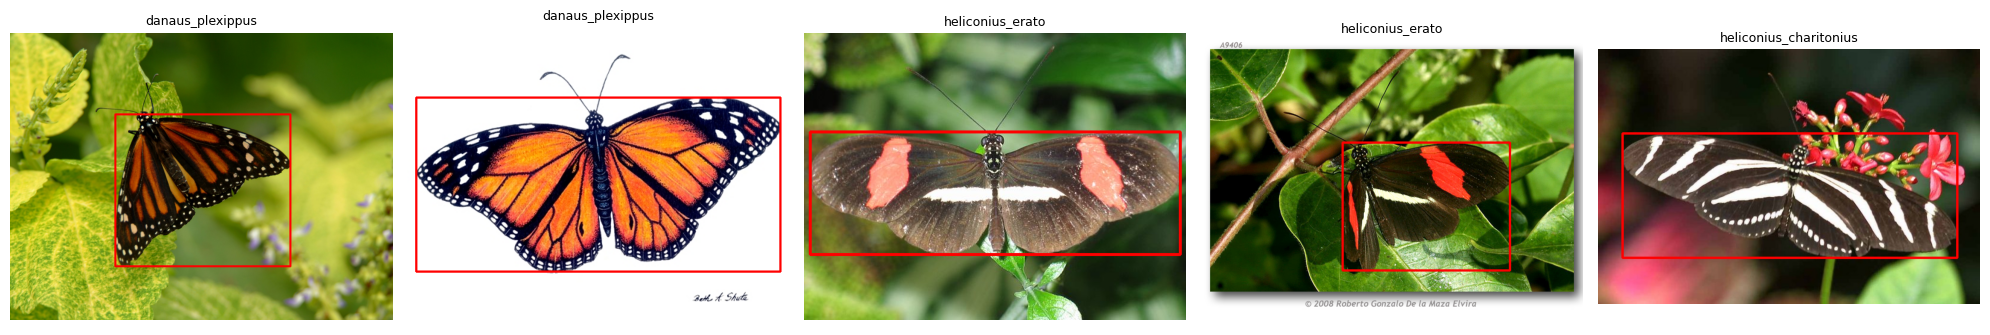

In [29]:
def draw_gt(image_path, label_path):
    image = cv2.cvtColor(cv2.imread(str(image_path)), cv2.COLOR_BGR2RGB)
    height, width = image.shape[:2]
    cls, cx, cy, bw, bh = map(float, label_path.read_text().split())
    x1, y1 = int((cx-bw/2)*width), int((cy-bh/2)*height)
    x2, y2 = int((cx+bw/2)*width), int((cy+bh/2)*height)
    cv2.rectangle(image, (x1,y1), (x2,y2), (255,0,0), max(2,width//200))
    return image, NAMES[int(cls)]

train_images = sorted((DATASET_DIR / "images/train").glob("*"))
sample = random.Random(SEED).sample(train_images, min(5, len(train_images)))
fig, axes = plt.subplots(1, len(sample), figsize=(4*len(sample),4))
axes = np.atleast_1d(axes)
for ax, path in zip(axes, sample):
    image, class_name = draw_gt(path, DATASET_DIR / "labels/train" / f"{path.stem}.txt")
    ax.imshow(image); ax.set_title(class_name, fontsize=9); ax.axis("off")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "ground_truth_examples.png", bbox_inches="tight", dpi=150)
plt.show()

## 2. Train baseline and controlled experiment

**Hypothesis:** reducing image size from 640 to 416 should reduce training time, with a possible small quality decrease because fine wing-pattern details may be less visible. We change only `imgsz`; other settings stay fixed. Both experiments use the same split, pretrained checkpoint, seed, epochs, batch size, and learning rate.

Both runs always train for the full 30 epochs unless early stopping fires; the number of epochs actually run is recorded in the results table. Training time is measured once per run on a shared Colab T4, so it is a rough indicator, not a precise benchmark.


In [ ]:
if not torch.cuda.is_available():
    raise RuntimeError("GPU is not available! In Colab: Runtime -> Change runtime type -> T4 GPU, then restart.")
DEVICE = 0
print("GPU:", torch.cuda.get_device_name(0))

EXPERIMENTS = {BASELINE_NAME: BASE_IMGSZ, EXPERIMENT_NAME: EXP_IMGSZ}
training_results = {}

for run_name, image_size in EXPERIMENTS.items():
    print("\n" + "=" * 60)
    print(f"Starting {run_name} | image size={image_size}")
    print("=" * 60)

    # Load the pretrained checkpoint BEFORE starting the timer, so the one-off
    # download of yolov8n.pt does not inflate the first run's training time.
    model = YOLO("yolov8n.pt")

    start_time = time.time()
    model.train(
        data=str(YAML), epochs=EPOCHS, imgsz=image_size, batch=BATCH, lr0=LR0,
        seed=SEED, device=DEVICE, project=str(ROOT / "runs" / "butterfly"), name=run_name,
        pretrained=True, workers=2, deterministic=True, plots=True, save=True,
        verbose=True, amp=True, cache=True, patience=10,
    )
    elapsed = time.time() - start_time

    run_dir = Path(model.trainer.save_dir)
    best_weights = run_dir / "weights" / "best.pt"
    assert best_weights.exists(), "Best model weights not found!"

    history = pd.read_csv(run_dir / "results.csv")
    history.columns = history.columns.str.strip()
    training_results[run_name] = {
        "image_size": image_size,
        "training_time_sec": elapsed,
        "epochs_run": int(len(history)),
        "best_epoch_by_val_mAP50-95": int(history["metrics/mAP50-95(B)"].idxmax()) + 1,
        "save_dir": str(run_dir),
        "best_weights": str(best_weights),
    }
    print(f"Finished in {elapsed / 60:.2f} min | epochs run: {len(history)}")

with open(RESULTS_DIR / "training_runs.json", "w") as f:
    json.dump(training_results, f, indent=2)
print("\nBoth experiments completed successfully!")


## 3. Validation evaluation and comparison

Use the validation split to compare the two experiments. The test split is reserved for the final selected model.

In [ ]:
def evaluate_model(run_name, image_size, split="val"):
    weights = Path(training_results[run_name]["best_weights"])
    model = YOLO(str(weights))
    metrics = model.val(
        data=str(YAML), split=split, imgsz=image_size, conf=EVAL_CONF, iou=EVAL_IOU,
        device=DEVICE, plots=True, verbose=False,
        project=str(ROOT / "runs" / "evaluation"), name=f"{run_name}_{split}", exist_ok=True
    )
    return {
        "run": run_name, "image_size": image_size, "split": split,
        "precision": float(metrics.box.mp), "recall": float(metrics.box.mr),
        "mAP50": float(metrics.box.map50), "mAP50-95": float(metrics.box.map),
        "training_time_min": training_results[run_name]["training_time_sec"] / 60,
        "epochs_run": training_results[run_name]["epochs_run"]
    }

val_results = [evaluate_model(name, size, "val") for name, size in EXPERIMENTS.items()]
val_df = pd.DataFrame(val_results)
val_df.to_csv(RESULTS_DIR / "validation_comparison.csv", index=False)
val_df

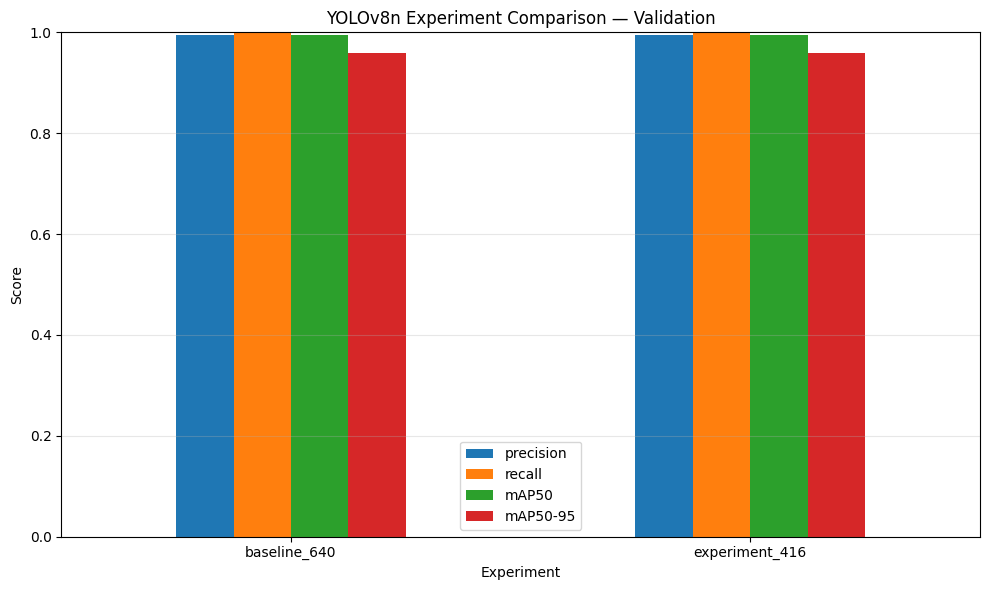

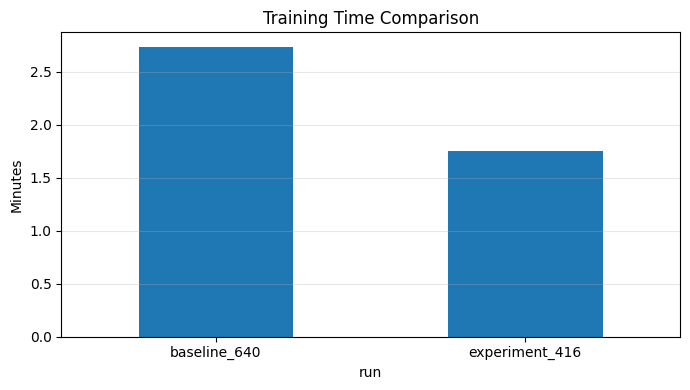

In [37]:
metric_columns = ["precision", "recall", "mAP50", "mAP50-95"]
ax = val_df.set_index("run")[metric_columns].plot(kind="bar", figsize=(10,6))
ax.set_title("YOLOv8n Experiment Comparison — Validation")
ax.set_ylabel("Score")
ax.set_ylim(0,1)
ax.set_xlabel("Experiment")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "validation_comparison.png", dpi=150)
plt.show()

# Training duration comparison
ax = val_df.set_index("run")["training_time_min"].plot(kind="bar", figsize=(7,4))
ax.set_title("Training Time Comparison")
ax.set_ylabel("Minutes")
plt.xticks(rotation=0); plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "training_time_comparison.png", dpi=150)
plt.show()

### 3.1 Select the final model (declared rule)

**Rule:** pick the run with the highest validation mAP50. Validation has only 62 images and mAP50 saturates near 0.995, so differences below `TIE_TOL` (0.005) are treated as a **tie**; on a tie the reference configuration (the 640 px baseline) is kept, because there is no evidence that the change helps. The test set is not used for selection.


In [ ]:
best_map50 = val_df["mAP50"].max()
tied = val_df[val_df["mAP50"] >= best_map50 - TIE_TOL]
if len(tied) > 1:
    FINAL_RUN = BASELINE_NAME if BASELINE_NAME in set(tied["run"]) else str(tied.iloc[0]["run"])
    selection_note = f"tie within {TIE_TOL} on val mAP50 -> keep baseline"
else:
    FINAL_RUN = str(tied.iloc[0]["run"])
    selection_note = "highest validation mAP50"

best_row = val_df[val_df["run"] == FINAL_RUN].iloc[0]
FINAL_SIZE = int(best_row["image_size"])
FINAL_WEIGHTS = Path(training_results[FINAL_RUN]["best_weights"])

print("Selected run:", FINAL_RUN, "|", selection_note)
print("Image size:", FINAL_SIZE, "| validation mAP50:", round(float(best_row["mAP50"]), 4))

FINAL_MODEL_PATH = RESULTS_DIR / "best.pt"
shutil.copy2(FINAL_WEIGHTS, FINAL_MODEL_PATH)
print("Saved final model:", FINAL_MODEL_PATH)

with open(RESULTS_DIR / "selected_model.json", "w") as f:
    json.dump({"selected_run": FINAL_RUN, "image_size": FINAL_SIZE,
               "selection_metric": "validation mAP50", "selection_note": selection_note,
               "tie_tolerance": TIE_TOL}, f, indent=2)


## 4. Final evaluation on the held-out test set

The model is selected using validation mAP50. Evaluate the chosen model on test only after selection. Metrics are computed with the evaluation confidence setting below. YOLO also saves plots such as the confusion matrix and precision/recall curves in its evaluation directory.

In [ ]:
final_model = YOLO(str(FINAL_MODEL_PATH))
test_metrics = final_model.val(
    data=str(YAML), split="test", imgsz=FINAL_SIZE, conf=EVAL_CONF, iou=EVAL_IOU,
    device=DEVICE, plots=True, verbose=False,
    project=str(ROOT / "runs" / "evaluation"), name="final_test", exist_ok=True
)

test_results = pd.DataFrame([{"selected_model": FINAL_RUN, "image_size": FINAL_SIZE,
    "precision": float(test_metrics.box.mp), "recall": float(test_metrics.box.mr),
    "mAP50": float(test_metrics.box.map50), "mAP50-95": float(test_metrics.box.map)}])
test_results.to_csv(RESULTS_DIR / "test_results.csv", index=False)
test_results

### 4.0 Per-class test metrics and saved plots

In [ ]:
per_class = pd.DataFrame({
    "class": [NAMES[int(i)] for i in test_metrics.box.ap_class_index],
    "AP50": test_metrics.box.ap50,
    "AP50-95": test_metrics.box.ap,
}).round(4)
per_class.to_csv(RESULTS_DIR / "test_per_class.csv", index=False)
display(per_class)

# Copy the plots that belong in the repo next to the CSV files
for run_name, info in training_results.items():
    src = Path(info["save_dir"]) / "results.png"
    if src.exists():
        shutil.copy2(src, RESULTS_DIR / f"training_curves_{run_name}.png")
for name in ["confusion_matrix_normalized.png", "confusion_matrix.png", "PR_curve.png"]:
    src = ROOT / "runs" / "evaluation" / "final_test" / name
    if src.exists():
        shutil.copy2(src, RESULTS_DIR / f"test_{name}")
print(sorted(p.name for p in RESULTS_DIR.iterdir()))


## 4.1 Visual predictions and ground truth on test images

Predicted boxes are drawn by Ultralytics. Ground-truth boxes are overlaid in green. This visualization is qualitative; the quantitative metrics above are the main evaluation.

In [ ]:
test_images = sorted((DATASET_DIR / "images/test").glob("*"))
assert test_images, "No test images found"

def read_gt(path):
    label_path = DATASET_DIR / "labels/test" / f"{path.stem}.txt"
    if not label_path.exists() or not label_path.read_text().strip():
        return []
    boxes = []
    for line in label_path.read_text().strip().splitlines():
        cls, cx, cy, bw, bh = map(float, line.split())
        boxes.append((int(cls), (cx-bw/2, cy-bh/2, cx+bw/2, cy+bh/2)))
    return boxes

def iou_xyxy(a, b):
    ix1, iy1 = max(a[0],b[0]), max(a[1],b[1])
    ix2, iy2 = min(a[2],b[2]), min(a[3],b[3])
    inter = max(0, ix2-ix1) * max(0, iy2-iy1)
    area_a = max(0,a[2]-a[0]) * max(0,a[3]-a[1])
    area_b = max(0,b[2]-b[0]) * max(0,b[3]-b[1])
    union = area_a + area_b - inter
    return inter / union if union > 0 else 0.0

def class_aware_match(gt_boxes, pred_boxes, iou_threshold=0.5):
    # For each GT, find the best prediction of the same class; one-to-one matching.
    used = set()
    outcomes = []
    for gt_cls, gt_box in gt_boxes:
        candidates = [(iou_xyxy(gt_box, p["box"]), j) for j,p in enumerate(pred_boxes)
                     if p["class"] == gt_cls and j not in used]
        best_iou, best_j = max(candidates, default=(0.0, None))
        if best_j is not None and best_iou >= iou_threshold:
            used.add(best_j)
            outcomes.append({"gt_class": gt_cls, "pred_class": gt_cls, "iou": best_iou, "matched": True})
        else:
            outcomes.append({"gt_class": gt_cls, "pred_class": None, "iou": best_iou, "matched": False})
    return outcomes

indices = random.Random(SEED).sample(range(len(test_images)), min(5, len(test_images)))
prediction_results = final_model.predict([str(p) for p in test_images], imgsz=FINAL_SIZE, conf=VIS_CONF, iou=EVAL_IOU, device=DEVICE, verbose=False)
fig, axes = plt.subplots(1, len(indices), figsize=(5*len(indices), 5))
axes = np.atleast_1d(axes)
visual_rows = []
for ax, idx in zip(axes, indices):
    path, pred = test_images[idx], prediction_results[idx]
    image = cv2.cvtColor(pred.plot(), cv2.COLOR_BGR2RGB)
    gt_boxes = read_gt(path)
    height, width = image.shape[:2]
    for cls_id, box in gt_boxes:
        x1,y1,x2,y2 = [int(round(v)) for v in (box[0]*width, box[1]*height, box[2]*width, box[3]*height)]
        cv2.rectangle(image, (x1,y1), (x2,y2), (0,255,0), 2)
        label = f"GT: {NAMES[cls_id]}"
        cv2.putText(image, label, (x1,max(18,y1-5)), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0,255,0), 1, cv2.LINE_AA)
    pred_boxes = []
    if pred.boxes is not None:
        for b in pred.boxes:
            pred_boxes.append({"class": int(b.cls.item()), "confidence": float(b.conf.item()), "box": tuple(b.xyxyn[0].cpu().numpy())})
    outcomes = class_aware_match(gt_boxes, pred_boxes)
    avg_iou = float(np.mean([o["iou"] for o in outcomes])) if outcomes else 0.0
    gt_labels = ", ".join(NAMES[c] for c,_ in gt_boxes)
    ax.imshow(image); ax.set_title(f"GT: {gt_labels}\nMatched IoU: {avg_iou:.2f}", fontsize=8); ax.axis("off")
    visual_rows.append({"image": path.name, "ground_truth": gt_labels, "mean_best_class_iou": avg_iou, "all_matched": all(o["matched"] for o in outcomes), "matched_count": sum(o["matched"] for o in outcomes), "gt_count": len(gt_boxes)})
plt.tight_layout()
plt.savefig(RESULTS_DIR / "test_predictions.png", bbox_inches="tight", dpi=150)
plt.show()

visual_df = pd.DataFrame(visual_rows)
visual_df.to_csv(RESULTS_DIR / "visual_sample_analysis.csv", index=False)
visual_df

## 4.2 Failure and hardest-case analysis (all 60 test images)

The sample above shows only 5 images, so it cannot say how many errors exist. Here every test image is checked: the highest-confidence prediction is compared with the ground-truth box (class-agnostic IoU) and class. Outcome labels: *correct*, *wrong class*, *poor localization* (IoU < 0.5), *missed* (no box at `VIS_CONF`). This is a top-1 view at `conf = 0.25`, so it differs slightly from the mAP computed at `conf = 0.001`. The script reports facts; the interpretation is written by hand below.


In [ ]:
rows = []
for path, pred in zip(test_images, prediction_results):
    gt_cls, gt_box = read_gt(path)[0]            # one butterfly per image in this dataset
    n_pred = 0 if pred.boxes is None else len(pred.boxes)
    if n_pred == 0:
        rows.append({"image": path.name, "gt": NAMES[gt_cls], "pred": None, "conf": 0.0,
                     "iou": 0.0, "n_pred": 0, "outcome": "missed"})
        continue
    top = int(pred.boxes.conf.argmax())
    b = pred.boxes[top]
    box = tuple(b.xyxyn[0].cpu().numpy())
    iou = iou_xyxy(gt_box, box)
    cls = int(b.cls.item())
    if cls != gt_cls and iou < 0.5: outcome = "wrong class + poor localization"
    elif cls != gt_cls:             outcome = "wrong class"
    elif iou < 0.5:                 outcome = "poor localization"
    else:                           outcome = "correct"
    rows.append({"image": path.name, "gt": NAMES[gt_cls], "pred": NAMES[cls],
                 "conf": float(b.conf.item()), "iou": iou, "n_pred": n_pred, "outcome": outcome})

analysis_df = pd.DataFrame(rows)
analysis_df.to_csv(RESULTS_DIR / "test_per_image_analysis.csv", index=False)

print(analysis_df["outcome"].value_counts().to_string())
print(f"\nMean top-1 IoU: {analysis_df['iou'].mean():.3f} | min: {analysis_df['iou'].min():.3f}")
print("Images with more than one box at conf >= %.2f: %d" % (VIS_CONF, (analysis_df['n_pred'] > 1).sum()))
print("\nConfusion (rows = ground truth, columns = top-1 prediction):")
print(pd.crosstab(analysis_df["gt"], analysis_df["pred"].fillna("none")).to_string())

# Hardest cases: errors first, then lowest IoU
hard = analysis_df.assign(is_error=analysis_df["outcome"] != "correct") \
                  .sort_values(["is_error", "iou"], ascending=[False, True]).head(3)
display(hard.drop(columns="is_error"))

fig, axes = plt.subplots(1, len(hard), figsize=(6 * len(hard), 6))
axes = np.atleast_1d(axes)
for ax, (_, row) in zip(axes, hard.iterrows()):
    idx = [p.name for p in test_images].index(row["image"])
    img = cv2.cvtColor(prediction_results[idx].plot(), cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    for cls_id, bx in read_gt(test_images[idx]):
        x1, y1, x2, y2 = [int(round(v)) for v in (bx[0]*w, bx[1]*h, bx[2]*w, bx[3]*h)]
        cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 2)
    ax.imshow(img); ax.axis("off")
    ax.set_title(f"{row['image']}\nGT: {row['gt']} | IoU {row['iou']:.2f} | {row['outcome']}", fontsize=9)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "hardest_test_cases.png", bbox_inches="tight", dpi=150)
plt.show()


### 4.3 Written analysis of the hardest cases (fill in after looking at the figure)

Look at `results/hardest_test_cases.png` and the table above, then replace the text in *italics*. Describe what you actually see; mark any cause as a hypothesis unless you tested it.

- **Case 1 —** *image name, IoU / outcome from the table; what is visible (background, wing angle, occlusion, box looser/tighter than the green GT box).*
- **Case 2 —** *same.*
- **Case 3 —** *same.*
- **One practical next step —** *one concrete change tied to what you saw (for example more varied backgrounds, augmentation, a second seed, a larger val/test set), and how you would check that it helped.*


## 5. Limitations

- Bounding boxes are derived from segmentation masks (pixel values 1 and 3 treated as butterfly) and can be imperfect.
- Only five of ten species are included; each image contains a single butterfly, so this is a constrained, fairly easy detection task.
- The validation set (62 images) and test set (60 images) are small, with 9-14 images per class in each; mAP50 saturates near 0.995 on validation, so the two experiments cannot be told apart on that metric.
- Perceptual hashing (distance <= 4) found only 5 near-duplicate pairs and may miss others.
- One random seed per experiment; small metric differences can be training variability.
- Training time comes from a single run on a shared Colab T4 (includes dataset caching and CUDA warm-up), so only a large gap is meaningful.
- Images were collected from Google Images; check the dataset terms on Zenodo before redistributing them.


## 6. Conclusion (generated from the saved results)

In [ ]:
from IPython.display import Markdown, display

v = val_df.set_index("run")
b, e = v.loc[BASELINE_NAME], v.loc[EXPERIMENT_NAME]
t = test_results.iloc[0]
d_map50, d_map5095 = e["mAP50"] - b["mAP50"], e["mAP50-95"] - b["mAP50-95"]
saving = 100 * (1 - e["training_time_min"] / b["training_time_min"])
quality = ("no meaningful difference in validation quality"
           if abs(d_map50) < TIE_TOL and abs(d_map5095) < 0.01
           else "a measurable difference in validation quality")

text = f"""**Experiment.** Reducing `imgsz` from 640 to 416 (all else fixed) changed validation mAP50 by {d_map50:+.3f} and mAP50-95 by {d_map5095:+.3f}: {quality}. Training took {e['training_time_min']:.2f} min instead of {b['training_time_min']:.2f} min ({saving:.0f}% less, single run). The hypothesis predicted a small quality drop; on this validation set it was not observed, but 62 images and one seed cannot confirm or rule out a small effect.

**Selection.** Final model: `{FINAL_RUN}` ({selection_note}).

**Test (held-out, evaluated once).** Precision {t['precision']:.3f}, recall {t['recall']:.3f}, mAP50 {t['mAP50']:.3f}, mAP50-95 {t['mAP50-95']:.3f}. Test-set numbers were not used to choose between the runs.

**Error analysis.** On all {len(analysis_df)} test images: {int((analysis_df['outcome'] == 'correct').sum())} correct at top-1 (conf >= {VIS_CONF}); mean top-1 IoU {analysis_df['iou'].mean():.3f}. See section 4.3 for the hardest cases.
"""
display(Markdown(text))
(RESULTS_DIR / "conclusion.md").write_text(text)
